# Statistical models on the torus, and conditioning

This notebook illustrates statistical models on amino acid torsion angles.

1. **Distributions on the torus**: classical distributions on the circle and torus are shown. Mixture models estimated on Alanine and Proline torsion angles are analyzed. These mixture models use circula based multivariate distributions as components.
2. **Conditioning on capping mechanism**: a mixture model estimated on Serine-Alanine amino-acid pairs is conditioned on a specific data subset. We select data representing non-helix-to-helix transition, as these display a phenomenon known as capping which has a noticeable influence on the side chain of Serine. Through a reweighting of the SERALA mixture model, we can obtain a conditioned density representative of the capping phenomenon.

In [1]:
import numpy as np
import pandas as pd
import copy

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import src.CBMD as CBMD
from src.plots import *

## 1. Toroidal models

In the following we display some classical statistical distributions on the circle.

### 1.1 Distributions on the circle (d=1)

#### Von mises distribution
The [von Mises distribution](https://en.wikipedia.org/wiki/Von_Mises_distribution) is a close analogue of the Normal distribution on the circle. 
Its density is expressed as:
$$
f(\theta \mid \mu, \kappa) =  \frac{\exp(\kappa \cos(\theta - \mu))}{2\pi I_0(\kappa}
$$

In [3]:
von_mises = CBMD.Von_mises(np.pi / 2 , 10)

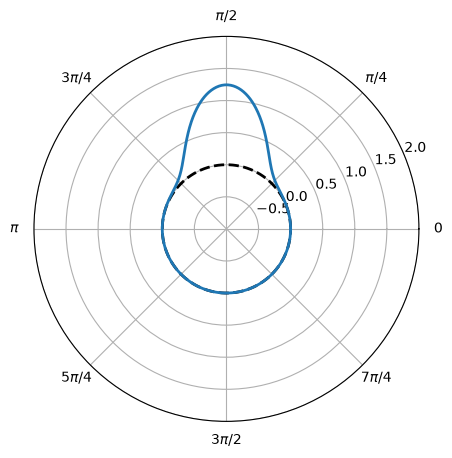

In [4]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, von_mises)

#### Wrapped cauchy distribution
The [wrapped Cauchy](https://en.wikipedia.org/wiki/Wrapped_Cauchy_distribution) distribution is obtained by wrapping an euclidian Cauchy distribution $\mathcal{C}$ on the circle as follows:
$$
f(\theta)=\sum_{k=-\infty}^{\infty}\mathcal{C}(\theta+2\pi k)
$$
This distribution is of interest because it can be expressed in the following (tractable) closed form:
$$
f(\theta \mid \mu, \rho) = \frac{1}{2\pi}\frac{1-\rho^2}{1+\rho^2-2\rho\cos(\theta-\mu)}
$$

In [5]:
wrapped_cauchy = CBMD.Wrapped_cauchy(np.pi / 2 , 0.75)

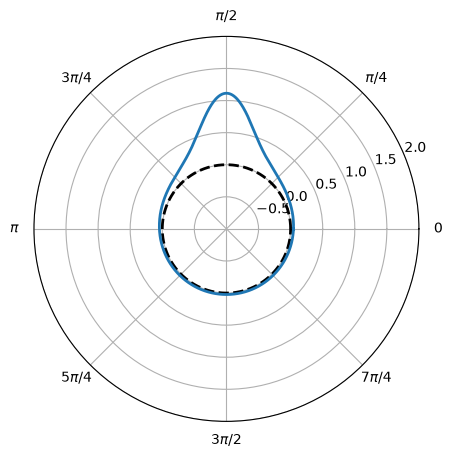

In [6]:
fig, ax = plt.subplots(figsize=(5,5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, wrapped_cauchy)

### 1.2 Distributions on the 2D Torus (d=2)

We move to distribution on the 2D Torus $T^2$, corresponding to two independent angles $S^1\times S^1$

In [7]:
resolution = 100
x = np.linspace(-np.pi, np.pi, resolution)
y = np.linspace(-np.pi, np.pi, resolution)

X, Y = np.meshgrid(x, y)
coords_2d = np.column_stack((X.ravel(), Y.ravel()))

#### Joint von mises
A naive way to obtain a distributions on a 2D Torus is to multiply two independent von Mises distribution.
$$
f(\theta_1, \theta_2) = vM_1(\theta_1) vM_2(\theta_2)
$$
Although this will obviously not be able to model correlation.

In [8]:
joint_von_mises = CBMD.Joint_von_mises([0, 0] , [5, 5])

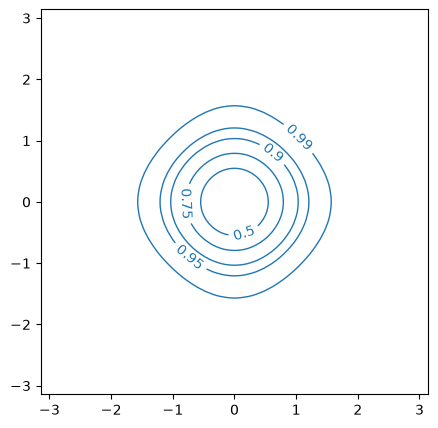

In [9]:
density = joint_von_mises.pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

#### Bivariate von Mises: no normalized closed form
The Bivariate von Mises is an extension of the von Mises to the 2D torus, able to capture correlation. Here we show the unnormalized density for the *sine* variant :
$$
f(\theta_1, \theta_2) \propto \exp \left(\kappa_1\cos(\theta_1-\mu_1) + \kappa_2\cos(\theta_2-\mu_2) + \lambda\sin(\theta_1-\mu_1)\sin(\theta_2-\mu_2)\right)
$$
Importantly, there is no closed form for the normalization constant, such that evaluating this distribution requires numerical approximations.

In [3]:
def bivariate_von_mises_unnormalized_pdf(values, mu, kappa, lam):
    return np.exp(kappa[0] * np.cos(values[0] - mu[0]) + 
                  kappa[1] * np.cos(values[1] - mu[1]) + 
                  lam * np.sin(values[0] - mu[0]) * np.sin(values[1] - mu[1]))

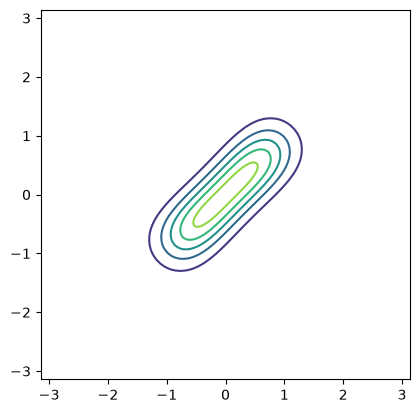

In [4]:
mu = [0,0]
kappa = [5,5]
lam = 5

unnorm_density = np.array([bivariate_von_mises_unnormalized_pdf(coord_2d, mu, kappa, lam) for coord_2d in coords_2d])
unnorm_density = unnorm_density.reshape(100, 100)


plt.xlim(-np.pi, np.pi)
plt.ylim(-np.pi, np.pi)
plt.gca().set_aspect('equal', adjustable='box')
plt.contour(X, Y, unnorm_density, levels=5)


### 1.3 Distributions on the d-Torus (d>2) : circula based multivariate distribution

For the general d-Torus, the Bivariate von Mises can be extended, resulting in the multivariate von Mises. However, the normalizing constant remains unknown, and approximating it is increasingly difficult as dimension increases.

#### Joint von Mises with wrapped Cauchy circula (vM-wC distribution)
The circula is an adaptation of [copulas](https://en.wikipedia.org/wiki/Copula_(statistics)) to periodic spaces. Copulas are distributions with uniform marginals that are able to model dependency structures. These distributions can be combined with individual marginal distributions through the [probability integral transform](https://en.wikipedia.org/wiki/Probability_integral_transform), to construct full distributions expressed as follows:
$$
f(\mathbf{\theta}) = f_1(\theta_1) \cdot ... \cdot f_d(\theta_d) \cdot C(F_1(\theta_1), ..., F_d(\theta_d)) 
$$
Where $f_i(\cdot)$ (resp. $F_i(\cdot)$) is the probability density (resp. cumulative distribution) function of the marginal distribution at dimension $i$, whereas $C$ is the copula density.
Using this principle, closed-forms circulas based on von Mises or wrapped Cauchy distributions can be derived. The resulting toroidal distributions remain tractable; but can capture dependency structures.
The following is a joint von mises combined with a wrapped Cauchy circula for $d=3$ (vM-wC distribution).

In [33]:
von_mises_1 = CBMD.Von_mises(0 , 5)
von_mises_2 = CBMD.Von_mises(0 , 5)
von_mises_3 = CBMD.Von_mises(1 , 2)

marginals = [von_mises_1, von_mises_2, von_mises_3]
qs =  [1.0, 1.0, -1.0]
rhos = [0.5, 0.5, 0.3]

vmwc_circula = CBMD.Wrapped_cauchy_CBMD(marginals, qs, rhos)

Projected confidence regions on dimensions [0,1]

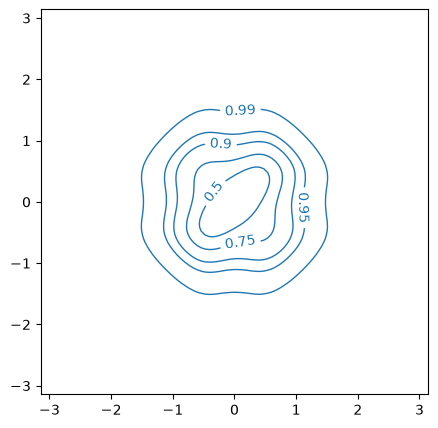

In [34]:
density = vmwc_circula.marginalize([0,1]).pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

Projected confidence regions on dimensions [0,2]

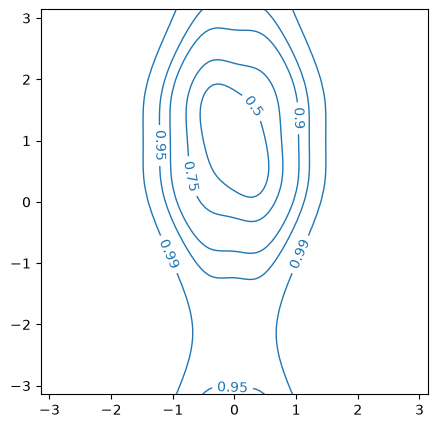

In [35]:
density = vmwc_circula.marginalize([0,2]).pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

### 1.4 d-Torus (d>2) : amino acid mixture models

#### Load ALA and PRO mixture models
A mixture model is expressed as a weighted sum of distributions :
$$
f(\theta) = \sum_{i=1}^K w_i p_i(\theta)
$$
where $w_i$ is the weight of component $i$; and $p_i(\cdot)$ is the density of component $i$.

The following mixture models represent Alanine and Proline torsion angles, and use vM-wC as component. The number of components is >100.

In [7]:
ALA_model = CBMD.Mixture_model.from_file("../models/VMWC_ALA_model.csv", component_type="VMWC")
PRO_model = CBMD.Mixture_model.from_file("../models/VMWC_PRO_model.csv", component_type="VMWC")


#### Generate samples
Generating a sample from a mixture model is done in two steps
1. Select a component $k$ from a categorical distribution with probabilities $w_1, ..., w_K$
2. Sample from the density $p_k(\cdot)$ of component $k$

In [8]:
ALA_sample = ALA_model.sample(size=10)
PRO_sample = PRO_model.sample(size=10)

#### Plot ALA

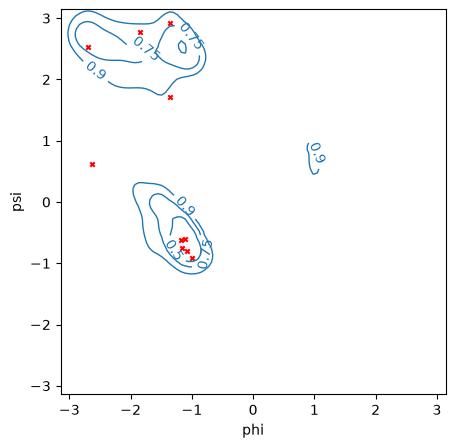

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, ALA_model, 0, 1, "phi", "psi")
ax.scatter(ALA_sample[:,0], ALA_sample[:,1], s=10, marker='x', color='red')

#### Plot PRO

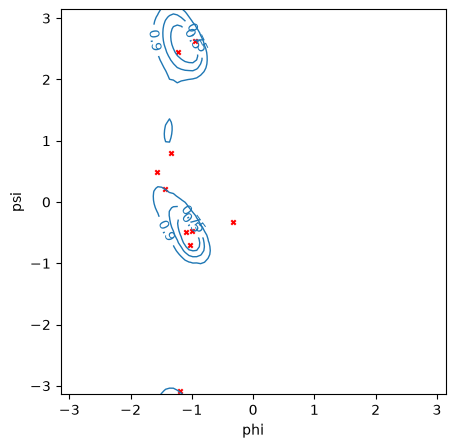

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, PRO_model, 0, 1, "phi", "psi")
ax.scatter(PRO_sample[:,0], PRO_sample[:,1], s=10, marker='x', color='red')

## 2. Conditioning SERALA model on the capping mechanism
In the following we will see how a mixture model can easily be conditioned to represent a data subset by a simple reweighting.

The data subset we select are Serine-Alanine residue pair in a not-helix-to-helix transition. This is because we wish to study the capping phenomenon [TODO].

### 2.1 Default SERALA model

We load the mixture model corresponding to Serine-Alanine pair in the general case. This is a model on 5 torsion angles ($\phi_1, \psi_1, \chi_1, \phi_2, \psi_2)$, the $\omega$ angle is excluded here)

#### Load SER-ALA pair model

In [9]:
SERALA_model = CBMD.Mixture_model.from_file("../models/VMWC_SER_ALA_model.csv", component_type="VMWC")

#### Generate sample

In [10]:
SERALA_sample = SERALA_model.sample(size=10)

#### Plot sample

We plot the mixture model projected on backbone angles.

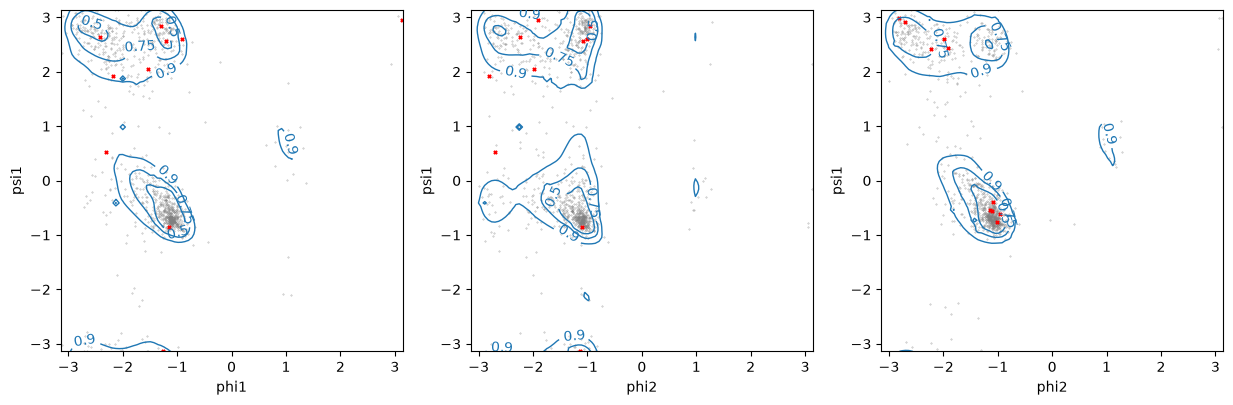

In [21]:
plot_serala_sample(SERALA_model, SERALA_sample)

Looking at the $\chi$ angle distribution of Serine shows no particular bias towards any of the three rotamers ($t, g-, g+$)

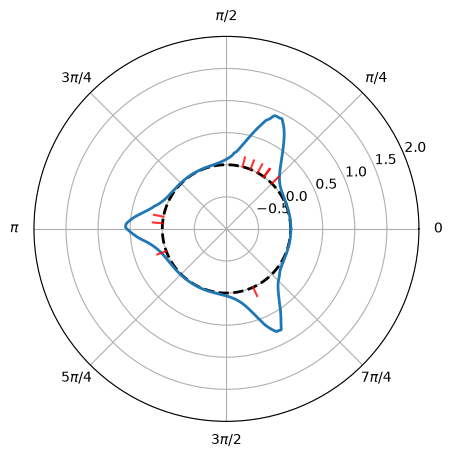

In [22]:
plot_serine_rotamer(SERALA_model, SERALA_sample)

The sample is visualized after an alignment on Serine to show the rotamer distribution on Serine.

In [23]:
visualize_serala_sample(SERALA_sample, "SERALA_sample", "../src/sbl-pdb-align.py")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 2.2 Condition SERALA model using capping data

#### Get capping dataset
We start by loading Serine-Alanine observations, annotated by Secondary Structure Element using DSSP.
These are around ~100k observations.

We create a capping data subset by selecting only observations where Serine is not in an helix and Alanine is in an Helix, corresponding to a transition.

In [24]:
#Load SERALA observations
SERALA_df = pd.read_csv("../data/SER_ALA_data")
#Select only observation where SER is not Helix and ALA is Helix (transition)
SERALA_helix_transition_df = SERALA_df[(SERALA_df["dssp1"] != 'H') & (SERALA_df["dssp2"] == 'H')]
SERALA_helix_transition_data = SERALA_helix_transition_df.drop(columns=["dssp1", "dssp2"]).to_numpy()

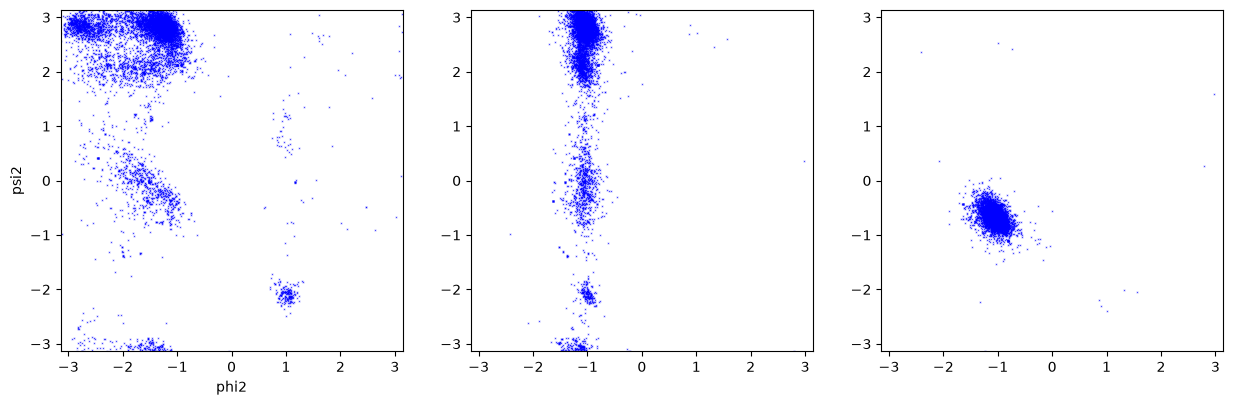

In [25]:
plot_serala_data(SERALA_helix_transition_data)

#### Condition SERALA model to capping

We condition the SERALA mixture model on this data subset to obtain a distribution on capping.
To do this we [TODO]

In [26]:
def compute_responsibilities(mm, sample):
    resps = np.zeros(shape=(sample.shape[0], len(mm.weights)))

    for i in range(len(mm.weights)):
        weight = mm.weights[i]
        component = mm.components[i]
        resps[:,i] = component.pdf(sample) * weight

    resps_sums = resps.sum(axis=1, keepdims=True)

    resps = resps / resps_sums
        
    return resps

In [27]:
# Compute component responsibility for each datapoint
responsibilities = compute_responsibilities(SERALA_model, SERALA_helix_transition_data)
responsibilities_sum = responsibilities.sum(axis=0)

In [28]:
# Reweight SERALA model using the component responsibilities
SERALA_helix_transition_model = copy.deepcopy(SERALA_model)
SERALA_helix_transition_weights = responsibilities_sum * SERALA_model.weights
SERALA_helix_transition_weights = SERALA_helix_transition_weights / SERALA_helix_transition_weights.sum()
SERALA_helix_transition_model.weights = SERALA_helix_transition_weights

Let's study our new mixture model

#### Generate capping sample

In [38]:
SERALA_helix_transition_sample = SERALA_helix_transition_model.sample(size=10)

#### Plot capping sample
We see the Alanine backbone angles are expectedly concentrated to the $\alpha$-helix region.

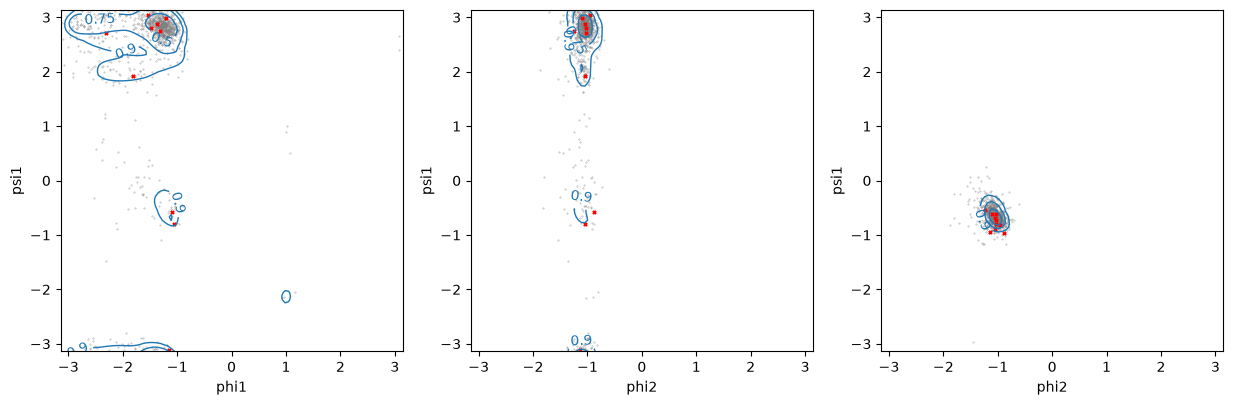

In [30]:
plot_serala_sample(SERALA_helix_transition_model, SERALA_helix_transition_sample)

There is now a clear bias towards the $g+$ rotamer on Serine, which is due specifically to capping.

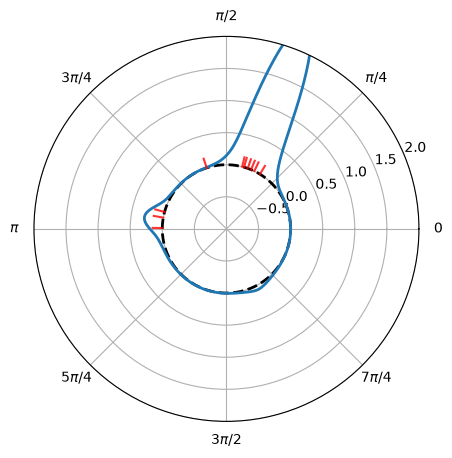

In [39]:
plot_serine_rotamer(SERALA_helix_transition_model, SERALA_helix_transition_sample)

In [40]:
visualize_serala_sample(SERALA_helix_transition_sample, "SERALA_helix_transition_sample", "../src/sbl-pdb-align.py")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.